In [158]:
import numpy as np
import csv
import matplotlib.pyplot as plt

#REYNOLDS NUMBER CALCULATION-----------------------------------------------------------------------------------------------------------------------------------------------------------

rho_cruise = 0.3796 #ISA
V_cruise = 0.85 * 296.5 #ISA
mu_cruise = 1.3885e-5 #NASA 
c_ref = 8.174 #VSP


Re = (rho_cruise * V_cruise * c_ref) / mu_cruise
print("Reynolds number at cruise conditions:", Re)


#LIFT COEFFICIENT CALCULATION-----------------------------------------------------------------------------------------------------------------------------------------------------------
m_cruise = 288818 * 0.9813
S_ref = 506.95 #reference area

C_Lcruise = m_cruise * 9.81 / (0.5 * rho_cruise * V_cruise**2 * S_ref)

#-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

data = {}
read_polar = False

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------

with open('Data/Correct_TE_CSV_files/Full_Payload_Full_Fuel_0.csv', 'r', encoding="utf-8-sig") as file: #Aero_Angle_0_Full_payload_Full_fuel.csv
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data)



#-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Reynolds number at cruise conditions: 56319472.240547344
{'Results_Timestamp': [1792491187.0], 'Results_Date': [10.0, 20.0, 2026.0], 'Results_Time': [12.0, 13.0, 7.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.010948325835, 0.006883603303, 0.003773061774, 0.001629140744, 0.000458689027, 0.000268288016, 0.00106241744, 0.002843319582, 0.005610057873, 0.009357503561, 0.014081862434, 0.019774708979, 0.026480162782, 0.034075471033, 0.042717821499, 0.052263922233], 'CDiw': [0.012854452016, 0.008064340233, 0.00440548218, 0.00189099132, 0.00053435078, 0.00034663263, 0.001337005195, 0.003511936406, 0.006875925048, 0.011429290499, 0.017175138859, 0.024112259862, 0.032274118146, 0.041557457207, 0.052149109218, 0.063880916962], 'CDo': [0.006825430039, 0.006194262629, 0.005710650698, 0.005375806159, 0.005190729638, 0.005155832612, 0.005271136009,

[0.85747824 0.84860112 0.82879528 0.76800653 0.47765554 0.12445122
 0.65374603 0.77404104 0.81077143 0.8260722  0.83352862 0.83747205
 0.83879562 0.8404092  0.84155584 0.84250469]


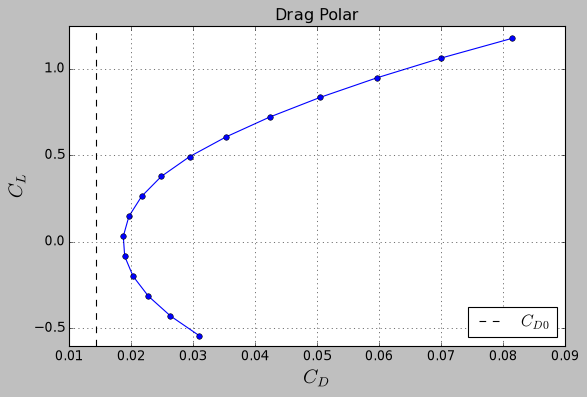

In [206]:
#DRAG POLAR PLOT ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

C_L = np.array(data['CLtot'], dtype=np.float64)
# print(C_L)
# print(C_L**2)

C_D0 = 0.01438

C_Di = np.array(data['CDi'])
# print(data['CDi'])

C_Dvisc = 0.38 * C_D0 * C_L**2

C_Dwave = []

for cl in C_L: 
    M_cruise = 0.85
    from scipy.interpolate import PchipInterpolator, CubicHermiteSpline
    ### your inputs here #############
    A_max = 88 #86 max cross sectional area 
    lam = 35 # leading edge sweep angle in degrees 
    l = 82.53 - (25-12)  # length of the fuselage where the curvature changes (use the cross-sectional area plot in VSP)
    S_ref = 506.95 #reference area
    Cl = cl #cruise lifT coef
    MddL0 = 0.87 # (0.6 thickness: 0.87) 0.855 readout from fig 12.29 in Raymer 0.855
    Mddfus = 0.82 #0.7865 before longation of nose readout from fig 12.31 in Raymer,  (2 L_n / d = 3.09) MEAN AREA USING 
    LF = 0.967 #(0.6 thickness: 0.967)   0.95 readout from fig 12.30 in Raymer 0.951
    ####################################
    Ewd = 1.8
    M_super= np.linspace(1.2, 2, 20)
    d_q_sh = 9*np.pi/2*(A_max/l)**2
    d_q_s = Ewd*(1-0.386*(M_super-1.2)**0.57*(1-(np.pi*lam**0.77)/100))*d_q_sh
    Cd_w_s = d_q_s/S_ref
    Cd_w_12 = d_q_s[0]/S_ref
    Cd_w_105 = Cd_w_12
    M_dd = min(MddL0*LF-0.05*Cl,Mddfus)
    M_cr = M_dd - 0.08
    M = [M_cr, M_dd,1.0, 1.05]
    M_1 = np.concatenate((M,M_super), axis=0)
    Cd_w = [0,0.002, (Cd_w_105)/2, Cd_w_105]
    Cd_1 = np.concatenate((Cd_w,Cd_w_s),axis=0)
    M_new = np.linspace(M_cr,2,100)
    # Cubic Hermite interpolation through the points: PCHIP slopes (no overshoot, no negative drag),
    # except at M=1.05 where the slope keeps the M=1.0-1.05 rise, giving the drag peak near M~1.1
    slopes = PchipInterpolator(M_1, Cd_1).derivative()(M_1)
    slopes[3] = 0.5*(Cd_1[3] - Cd_1[2]) / (M_1[3] - M_1[2])
    cd_smooth = CubicHermiteSpline(M_1, Cd_1, slopes)

    if M_cruise <= M_cr:
        C_D_wave_085 = 0.0  
    else:
        C_D_wave_085 = float(cd_smooth(M_cruise))
        C_Dwave.append(C_D_wave_085)

C_Dwave = np.array(C_Dwave, dtype=np.float64)

C_D = C_D0 + C_Di + C_Dvisc + C_Dwave
# print(C_D)

e = C_L**2 / (np.pi * 10 * C_Di)
print(e)

plt.style.use('classic') # Set the style for the plots
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(C_D, C_L, color='blue', marker='o', markersize=5, linestyle='-')
ax.set_ylim([-0.6, 1.25])
#Mark C_D0 with vertical black dashed line
ax.axvline(x=C_D0, color='black', linestyle='--', label='$C_{D0}$')
ax.set_xlabel('$C_D$', fontsize=18)
ax.set_ylabel('$C_L$', fontsize=18)
ax.set_title('Drag Polar')
ax.legend(loc='lower right', fontsize=15)
ax.grid()

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Required angle of attack at cruise: 3.6701440107998162


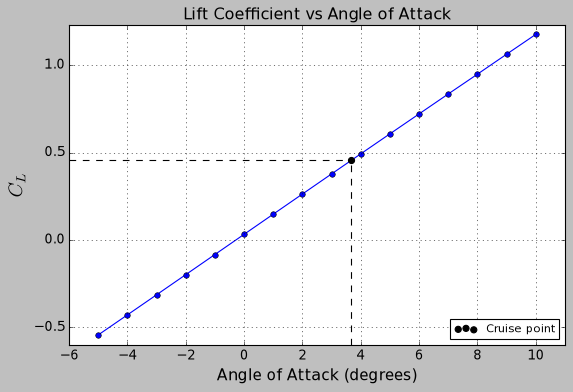

In [201]:
#LIFT COEFFICIENT vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
alpha_cruise = np.interp(C_Lcruise, data['CLtot'], data['Alpha'])
print("Required angle of attack at cruise:", alpha_cruise)

ax.plot(data['Alpha'], data['CLtot'], color='blue', marker='o', markersize=5, linestyle='-')
ax.hlines(y=C_Lcruise, xmin=ax.get_xlim()[0], xmax=alpha_cruise, color='black', linestyle='--')
ax.vlines(x=alpha_cruise, ymin=ax.get_ylim()[0], ymax=C_Lcruise, color='black', linestyle='--')
ax.scatter(alpha_cruise, C_Lcruise, color='black', marker='o', s=30, label = 'Cruise point', zorder=5)
ax.set_ylim([-0.6, 1.23])
ax.set_xlim([-6, 11])
ax.set_title('Lift Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=14)
ax.set_ylabel('$C_L$', fontsize=18)
ax.legend(loc='lower right', fontsize=10)
ax.grid()


#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

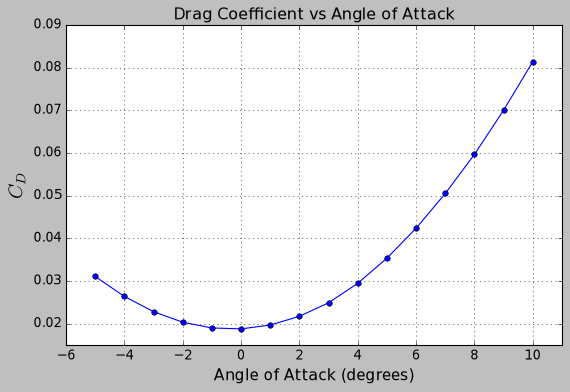

In [174]:
#DRAG COEFFICIENT ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['Alpha'], C_D, color='blue', marker='o', markersize=5, linestyle='-')
ax.set_xlim([-6, 11])
ax.set_ylim([0.015, 0.09])
ax.set_title('Drag Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=14)
ax.set_ylabel('$C_D$', fontsize=18)

ax.grid()

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

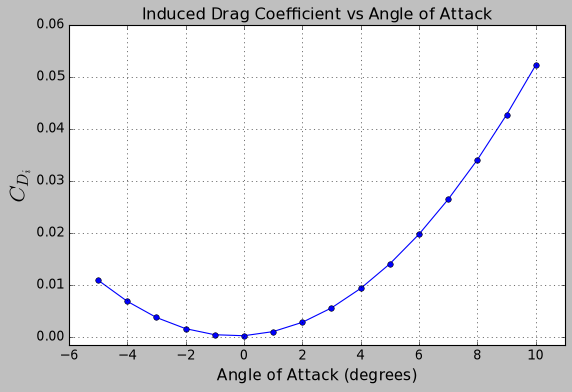

In [177]:
#INDUCED DRAG COEFFICIENT vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(data['Alpha'], C_Di, color='blue', marker='o', markersize=5, linestyle='-')
ax.set_ylim(-0.0015, 0.06)
ax.set_xlim([-6, 11])

ax.set_title('Induced Drag Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=14)
ax.set_ylabel('$C_{D_i}$', fontsize=20)

ax.grid()

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

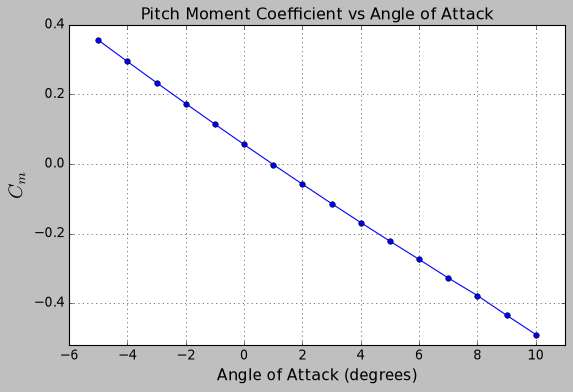

In [171]:
#PITCH MOMENT COEFFICIENT vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(data['Alpha'], data['CMytot'], color='blue', markersize=5, marker='o')
ax.set_xlim([-6, 11])
ax.set_ylim([-0.52, 0.4])
ax.set_title('Pitch Moment Coefficient vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=14)
ax.set_ylabel('$C_m$', fontsize=18)

ax.grid()

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Lift-to-Drag ratio: [-17.49355311 -16.24469832 -13.7505416   -9.75293422  -4.37098822
   1.72655044   7.5112162   12.11433416  15.19637263  16.73299762
  17.17978201  17.03221322  16.54077658  15.89670444  15.17598526
  14.44732721]
Alpha at cruise: 3.670 degrees
L/D at cruise: 16.226


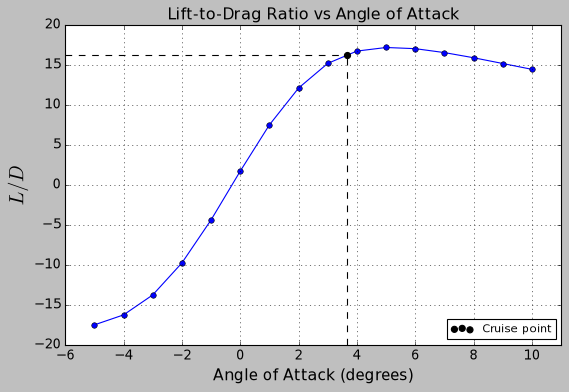

In [202]:
#L/D RATIO vs ALPHA ------------------------------------------------------------------------------------------------------------------------------------------------------------------------


LD = C_L / C_D
print("Lift-to-Drag ratio:", LD)

print(f"Alpha at cruise: {alpha_cruise:.3f} degrees")

LD_cruise = np.interp(alpha_cruise, data['Alpha'], LD)
print(f"L/D at cruise: {LD_cruise:.3f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlim([-6, 11])
ax.set_ylim([-20, 20])
ax.plot(data['Alpha'], LD, color='blue', marker='o', markersize=5, linestyle='-')
ax.vlines(x=alpha_cruise, ymin=ax.get_ylim()[0], ymax=LD_cruise, color='black', linestyle='--')
ax.hlines(y=LD_cruise, xmin=ax.get_xlim()[0], xmax=alpha_cruise, color='black', linestyle='--')
ax.scatter(alpha_cruise, LD_cruise, color='black', marker='o', s=30, label = 'Cruise point', zorder=5)
ax.set_title('Lift-to-Drag Ratio vs Angle of Attack')
ax.set_xlabel('Angle of Attack (degrees)', fontsize=14)
ax.set_ylabel('$L/D$', fontsize=18)
ax.legend(loc='lower right', fontsize=10)
ax.grid()

#----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

Required lift coefficient at cruise conditions: 0.4549319936369352
Required pitch moment coefficient at cruise conditions: -0.15017422139522063


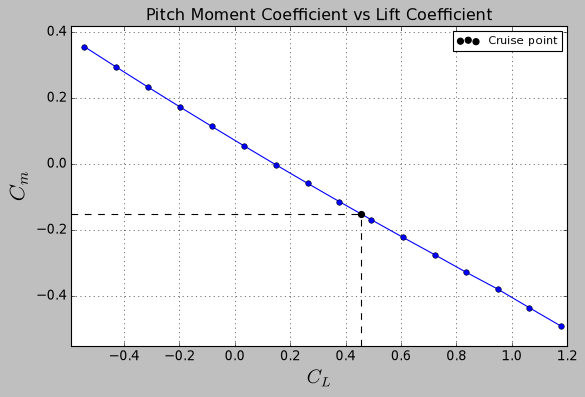

In [210]:
#Pitch moment coefficient vs lift coefficient -------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_cruise = 288818 * 0.9813
S_ref = 506.95 #reference area

C_Lcruise = m_cruise * 9.81 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
Cm_cruise = np.interp(C_Lcruise, data['CLtot'], data['CMytot'])
print("Required lift coefficient at cruise conditions:", C_Lcruise)
print("Required pitch moment coefficient at cruise conditions:", Cm_cruise)


fig, ax = plt.subplots(figsize=(8, 5))
ax.set_ylim([-0.55, 0.42])
ax.set_xlim([-0.59, 1.2])
ax.plot(data['CLtot'], data['CMytot'], color='blue', marker='o', markersize=5, linestyle='-')
ax.scatter(C_Lcruise, Cm_cruise, color='black', marker='o', s=30, label = 'Cruise point', zorder=5)
ax.vlines(x=C_Lcruise, ymin=ax.get_ylim()[0], ymax=Cm_cruise, color='black', linestyle='--', zorder=5)
ax.hlines(y=Cm_cruise, xmin=ax.get_xlim()[0], xmax=C_Lcruise, color='black', linestyle='--', zorder=5)
ax.set_title('Pitch Moment Coefficient vs Lift Coefficient')
ax.set_xlabel('$C_L$', fontsize=18)
ax.set_ylabel('$C_m$', fontsize=20)
ax.legend(loc='upper right', fontsize=10)
ax.grid()



{'Results_Timestamp': [1792491974.0], 'Results_Date': [10.0, 20.0, 2026.0], 'Results_Time': [12.0, 26.0, 14.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.00847383379, 0.004723651227, 0.001876526605, -5.2530322e-05, -0.001051276343, -0.00111453144, -0.000230419903, 0.001601208466, 0.004379787194, 0.008098112912, 0.012749795543, 0.018318557778, 0.02484377914, 0.032112987451, 0.040323406931, 0.049737659777], 'CDiw': [0.009856342724, 0.00612403197, 0.003525707101, 0.002075064625, 0.001785739358, 0.002667320949, 0.004728935296, 0.007975650796, 0.012411384717, 0.018037886605, 0.024860406989, 0.032869933263, 0.042070470368, 0.052322412415, 0.063902673913, 0.07665181247], 'CDo': [0.006725154797, 0.006136520551, 0.005695020943, 0.005401917781, 0.005258111894, 0.005263909569, 0.00541924655, 0.005723597831, 0.00617584545, 0.006774590196, 0.0075

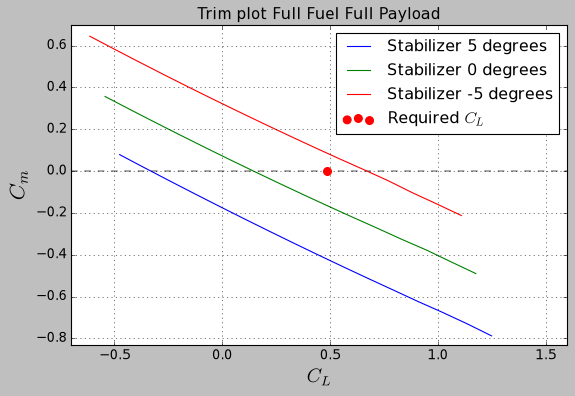

In [166]:
data5 = {}
read_polar = False

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------

with open('Data/Correct_TE_CSV_files/Full_Payload_Full_Fuel_5.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data5)



datamin5 = {}
read_polar = False

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------

with open('Data/Correct_TE_CSV_files/Full_Payload_Full_Fuel_-5.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            datamin5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

            
print(datamin5)

# TRIM PLOT FULL FUEL FULL PAYLOAD ------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_fullfuelfullpayload = 303785.80 #ADD LANDING GEAR AS WELL!!!
S_ref = 506.95
C_L_fullfuelfullpayload = m_fullfuelfullpayload * 9.82 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
print("Trim point for full fuel and full payload: C_L =", C_L_fullfuelfullpayload)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_ylim([-0.83, 0.7])
ax.set_xlim([-0.7, 1.6])
ax.set_title('Trim plot Full Fuel Full Payload', fontsize=14)
ax.plot(data5['CLtot'], data5['CMytot'], color='blue', markersize=5, linestyle='-', label = 'Stabilizer 5 degrees')
ax.plot(data['CLtot'], data['CMytot'], color='green', markersize=5, linestyle='-', label = 'Stabilizer 0 degrees')
ax.plot(datamin5['CLtot'], datamin5['CMytot'], color='red', markersize=5, linestyle='-', label = 'Stabilizer -5 degrees')
ax.scatter(C_L_fullfuelfullpayload, 0, color='red', marker='o', s=50, label = 'Required $C_L$', zorder=5)
ax.set_xlabel('$C_L$', fontsize=18)
ax.set_ylabel('$C_m$', fontsize=20)
ax.legend()
ax.grid()
#Make grid line at C_m = 0 thicker
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, zorder=0, alpha=0.4)



{'Results_Timestamp': [1792493208.0], 'Results_Date': [10.0, 20.0, 2026.0], 'Results_Time': [12.0, 46.0, 48.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.010948325835, 0.006883603303, 0.003773061774, 0.001629140744, 0.000458689027, 0.000268288016, 0.00106241744, 0.002843319582, 0.005610057873, 0.009357503561, 0.014081862434, 0.019774708979, 0.026480162782, 0.034075471033, 0.042717821499, 0.052263922233], 'CDiw': [0.012854452016, 0.008064340233, 0.00440548218, 0.00189099132, 0.00053435078, 0.00034663263, 0.001337005195, 0.003511936406, 0.006875925048, 0.011429290499, 0.017175138859, 0.024112259862, 0.032274118146, 0.041557457207, 0.052149109218, 0.063880916962], 'CDo': [0.006825430039, 0.006194262629, 0.005710650698, 0.005375806159, 0.005190729638, 0.005155832612, 0.005271136009, 0.005536163706, 0.005950065972, 0.006511261065, 0.00721

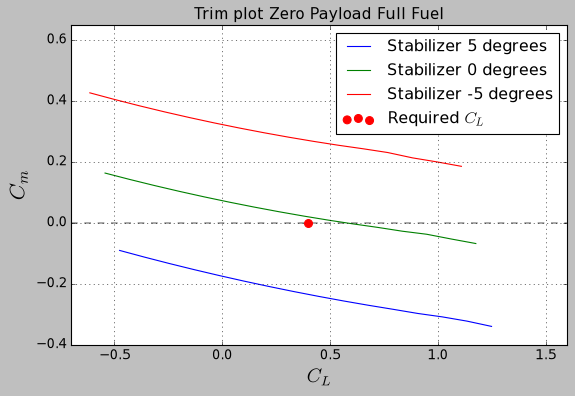

In [167]:

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------


data0 = {}
read_polar = False

with open('Data/Correct_TE_CSV_files/Zero_Payload_Full_fuel_0.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data0[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data0)





data5 = {}
read_polar = False

with open('Data/Correct_TE_CSV_files/Zero_Payload_Full_fuel_5.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data5)



datamin5 = {}
read_polar = False



with open('Data/Correct_TE_CSV_files/Zero_Payload_Full_fuel_-5.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)
    

    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            datamin5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

            
print(datamin5)

# TRIM PLOT ZERO PAYLOAD FULL FUEL------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_zeropayloadfullfuel = 248735.80 
S_ref = 506.95
C_L_zeropayloadfullfuel = m_zeropayloadfullfuel * 9.82 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
print("Trim point for zero payload and full fuel: C_L =", C_L_zeropayloadfullfuel)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_ylim([-0.4, 0.65])
ax.set_xlim([-0.7, 1.6])
ax.set_title('Trim plot Zero Payload Full Fuel', fontsize=14)
ax.plot(data5['CLtot'], data5['CMytot'], color='blue', markersize=5, linestyle='-', label = 'Stabilizer 5 degrees')
ax.plot(data0['CLtot'], data0['CMytot'], color='green', markersize=5, linestyle='-', label = 'Stabilizer 0 degrees')
ax.plot(datamin5['CLtot'], datamin5['CMytot'], color='red', markersize=5, linestyle='-', label = 'Stabilizer -5 degrees')
ax.scatter(C_L_zeropayloadfullfuel, 0, color='red', marker='o', s=50, label = 'Required $C_L$', zorder=5)
ax.set_xlabel('$C_L$', fontsize=18)
ax.set_ylabel('$C_m$', fontsize=20)
ax.legend()
ax.grid()
#Make grid line at C_m = 0 thicker
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, zorder=0, alpha=0.4)



{'Results_Timestamp': [1792494750.0], 'Results_Date': [10.0, 20.0, 2026.0], 'Results_Time': [13.0, 12.0, 30.0], 'Alpha': [-5.0, -4.0, -3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'Beta': [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], 'CDi': [0.010948325835, 0.006883603303, 0.003773061774, 0.001629140744, 0.000458689027, 0.000268288016, 0.00106241744, 0.002843319582, 0.005610057873, 0.009357503561, 0.014081862434, 0.019774708979, 0.026480162782, 0.034075471033, 0.042717821499, 0.052263922233], 'CDiw': [0.012854452016, 0.008064340233, 0.00440548218, 0.00189099132, 0.00053435078, 0.00034663263, 0.001337005195, 0.003511936406, 0.006875925048, 0.011429290499, 0.017175138859, 0.024112259862, 0.032274118146, 0.041557457207, 0.052149109218, 0.063880916962], 'CDo': [0.006825430039, 0.006194262629, 0.005710650698, 0.005375806159, 0.005190729638, 0.005155832612, 0.005271136009, 0.005536163706, 0.005950065972, 0.006511261065, 0.00721

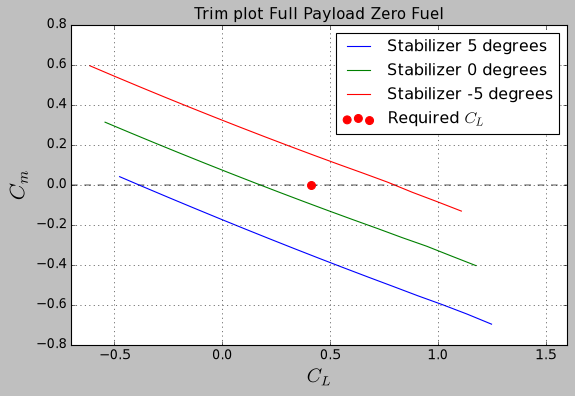

In [168]:

#IMPORT DATA FROM AERO.CSV ---------------------------------------------------------------------------------------------------------------------------------------------------------------


data0 = {}
read_polar = False

with open('Data/Correct_TE_CSV_files/Full_Payload_Zero_Fuel_0.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data0[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data0)





data5 = {}
read_polar = False

with open('Data/Correct_TE_CSV_files/Full_Payload_Zero_Fuel_5.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)


    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            data5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

print(data5)



datamin5 = {}
read_polar = False




with open('Data/Correct_TE_CSV_files/Full_Payload_Zero_Fuel_-5.csv', 'r', encoding="utf-8-sig") as file:
    reader = csv.reader(file)
    

    for row in reader: 


        if row[0] == 'Results_Name' and row[1] == 'VSPAERO_Polar':
            read_polar = True
            continue

        if read_polar and row[0] == 'Results_Name':
            break

        if read_polar and not row[0].startswith('Results_Name'):
            datamin5[row[0]] = [
                            float(value) if value.strip() else np.nan
                            for value in row[1:]
                            ]

            
print(datamin5)

# TRIM PLOT ZERO PAYLOAD FULL FUEL------------------------------------------------------------------------------------------------------------------------------------------------------------------------

m_fullpayloadzerofuel = 255511.87
S_ref = 506.95
C_L_fullpayloadzerofuel = m_fullpayloadzerofuel * 9.82 / (0.5 * rho_cruise * V_cruise**2 * S_ref)
print("Trim point for full payload and zero fuel: C_L =", C_L_fullpayloadzerofuel)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('Trim plot Full Payload Zero Fuel', fontsize=14)
ax.set_ylim([-0.8, 0.8])
ax.set_xlim([-0.7, 1.6])
ax.plot(data5['CLtot'], data5['CMytot'], color='blue', markersize=5, linestyle='-', label = 'Stabilizer 5 degrees')
ax.plot(data0['CLtot'], data0['CMytot'], color='green', markersize=5, linestyle='-', label = 'Stabilizer 0 degrees')
ax.plot(datamin5['CLtot'], datamin5['CMytot'], color='red', markersize=5, linestyle='-', label = 'Stabilizer -5 degrees')
ax.scatter(C_L_fullpayloadzerofuel, 0, color='red', marker='o', s=50, label = 'Required $C_L$', zorder=5)
ax.set_xlabel('$C_L$', fontsize=18)
ax.set_ylabel('$C_m$', fontsize=20)
ax.legend()
ax.grid()
#Make grid line at C_m = 0 thicker
ax.axhline(y=0, color='black', linestyle='--', linewidth=1.5, zorder=0, alpha=0.4)



Text(0.5, 1.0, 'Mass vs CG location')

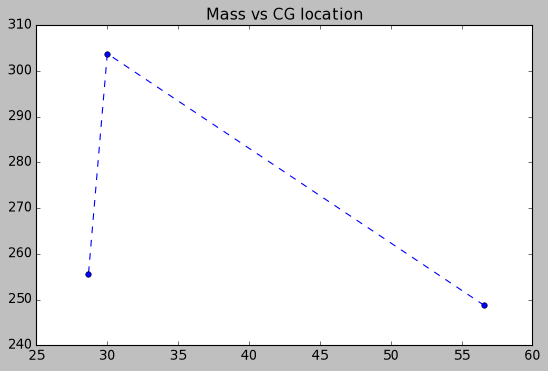

In [169]:
masses = np.array([303785.80, 248735.8, 255511.87]) #full payload full fuel, Zero payload full fuel, full payload zero fuel
cg_MAC = np.array([0.30, 0.5659, 0.2867]) #full fuel full payload, zero payload full fuel, full payload zero fuel

fig, ax = plt.subplots(figsize=(8, 5))
order = [1, 0, 2]
ax.plot(
    cg_MAC[order] * 100, masses[order] / 1000,
    color='blue', linestyle='--', marker='o', markersize=5
)
ax.set_title('Mass vs CG location', fontsize=14)   